# Stage 4 — Candidate marker discovery

**Pipeline stage 4 of 5**: patient-level split → phase segmentation → train + explain →
**candidate discovery** → confirm & report.

Turns Stage 3's out-of-fold Grad-CAM heatmaps and Stage 2's phase boundaries into candidate
acoustic markers — combinations of **phase** (S1/systole-early/.../diastole-late), **frequency
band**, and **auscultation site** where MI and Normal patients' heatmap energy genuinely
differs. A candidate only survives to the final report if it passes *four* separate checks,
each done here:

1. **Recurs across many patients** — tested at the patient level, not recording level (a
   patient's segments/sites are correlated, not independent samples).
2. **Not a one-fold fluke** — direction of the effect checked separately using each fold's own
   held-out patients.
3. **Statistically real** — Mann-Whitney U test + Cliff's delta effect size per candidate cell,
   with Benjamini-Hochberg correction across every cell tested (dozens of phase x frequency x
   site combinations are being compared at once — without correction, some would look
   "significant" by chance alone).
4. **Causally load-bearing, not just correlated** — occlusion testing: mask exactly this region
   in the input and see whether the classifier's accuracy drops more than it does when masking
   a random region of the same size.

This mirrors the pipeline sketched earlier: Grad-CAM points at *candidates*, it doesn't
validate them — steps 3 and 4 here are what do that.

**Everything in this notebook runs on the development set only.** Whatever survives all four
checks is a *development-set candidate marker* — Stage 5 is what actually confirms it, once, on
the locked cohort nothing here has touched.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ---- Setup ----------------------------------------------------------------
import sys
import json
import datetime
import pathlib

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

package_path = "/content/drive/MyDrive/Research 2026/mi_marker_pipeline"
if package_path not in sys.path:
    sys.path.insert(0, package_path)

from pipeline_common import config
from pipeline_common.features import n_freq_bins
from pipeline_common.models import make_model
from pipeline_common.discovery import (
    generate_frequency_bands, compute_recording_energy_table, aggregate_to_patient_level,
    run_statistical_tests, check_fold_stability, run_occlusion_test,
)

import random
random.seed(config.SEED); np.random.seed(config.SEED); torch.manual_seed(config.SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEG_DIR = config.ARTIFACTS_DIR / "02_segmentation" / "heuristic"
TRAIN_DIR = config.ARTIFACTS_DIR / "03_train_explain"
STAGE_DIR = config.ARTIFACTS_DIR / "04_candidate_discovery"
STAGE_DIR.mkdir(parents=True, exist_ok=True)

PHASE_ORDER = ["S1", "systole_early", "systole_mid", "systole_late",
              "S2", "diastole_early", "diastole_mid", "diastole_late"]

print("Using device:", DEVICE)
print("Saving this stage's output to:", STAGE_DIR)

Using device: cuda
Saving this stage's output to: /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/04_candidate_discovery


## 1. Load Stage 2 + Stage 3 outputs

In [4]:
boundaries_df = pd.read_csv(SEG_DIR / "phase_boundaries.csv")
oof_df = pd.read_csv(TRAIN_DIR / "out_of_fold_predictions.csv")
cams_array = np.load(TRAIN_DIR / "gradcam_heatmaps.npz")["cams"]
assert len(oof_df) == cams_array.shape[0], "predictions and heatmaps must stay row-aligned"

N_FREQ_BINS = n_freq_bins()
fold_models = {}
for k in range(config.N_FOLDS):
    m = make_model(N_FREQ_BINS, DEVICE)
    m.load_state_dict(torch.load(TRAIN_DIR / "models" / f"fold_{k}.pt", map_location=DEVICE))
    m.eval()
    fold_models[k] = m

print(f"{len(boundaries_df)} phase-boundary rows, {len(oof_df)} out-of-fold explanations, "
      f"{len(fold_models)} fold models loaded")

150640 phase-boundary rows, 2688 out-of-fold explanations, 5 fold models loaded


## 2. Heatmap energy by phase x frequency-band x site

Frequency bands are fixed, round numbers decided in advance (`FREQUENCY_BAND_WIDTH_HZ` =
100 Hz by default) — not searched over — so the choice of bin edges isn't itself a hidden
extra multiple comparison stacked on top of the (phase, site) search.

In [5]:
freq_bands = generate_frequency_bands(config.FREQUENCY_HIGH, config.FREQUENCY_BAND_WIDTH_HZ)
print("Frequency bands (Hz):", freq_bands)

recording_energy_df = compute_recording_energy_table(
    oof_df, cams_array, boundaries_df, freq_bands,
    config.FREQUENCY_HIGH, config.CLIP_SECONDS, aggregation=config.ENERGY_AGGREGATION,
)
patient_energy_df = aggregate_to_patient_level(recording_energy_df)

print(f"{len(recording_energy_df)} recording-level energy rows "
      f"-> {len(patient_energy_df)} patient-level rows after aggregation")
print(f"({patient_energy_df['patient_id'].nunique()} patients x "
      f"{patient_energy_df['site'].nunique()} site(s) x 8 phases x {len(freq_bands)} bands, "
      f"minus any cells a patient had no recordings for)")

Frequency bands (Hz): [(0.0, 100.0), (100.0, 200.0), (200.0, 300.0), (300.0, 400.0), (400.0, 500.0), (500.0, 600.0), (600.0, 700.0), (700.0, 800.0)]
171520 recording-level energy rows -> 28608 patient-level rows after aggregation
(112 patients x 4 site(s) x 8 phases x 8 bands, minus any cells a patient had no recordings for)


## 3. Statistical testing (Mann-Whitney U + Cliff's delta + FDR)

One test per (site, phase, frequency-band) cell, corrected across all of them together.

In [6]:
results_df = run_statistical_tests(
    patient_energy_df, min_patients_per_group=config.MIN_PATIENTS_PER_GROUP_FOR_TEST,
    alpha=config.FDR_ALPHA,
)

n_testable = (~results_df["insufficient_data"]).sum()
n_significant = results_df["significant"].sum()
print(f"{len(results_df)} cells total, {n_testable} had enough patients to test, "
      f"{n_significant} significant after FDR correction (q < {config.FDR_ALPHA})")

if n_testable > 0:
    print("\nMost significant cells (by raw p-value, before deciding which are stable/causal):")
    print(results_df[~results_df["insufficient_data"]].sort_values("p_value").head(10)
          [["site", "phase_label", "freq_low", "freq_high", "n_mi", "n_normal",
           "median_mi", "median_normal", "cliffs_delta", "p_value", "fdr_q_value", "significant"]])
else:
    # Diagnostics: 0 testable cells out of many is unexpected once you have a real patient
    # count -- this block exists to show WHERE the patient counts are actually going, so a
    # site-sparsity or coverage problem is visible immediately instead of just "0 significant".
    print("\nNo cells had enough patients to test -- diagnostics below:")
    print(f"\nMIN_PATIENTS_PER_GROUP_FOR_TEST = {config.MIN_PATIENTS_PER_GROUP_FOR_TEST}")
    print(f"\nUnique patients per (site, class), in patient_energy_df:")
    print(patient_energy_df.groupby(["site", "class_name"])["patient_id"].nunique().unstack(fill_value=0))
    print(f"\nn_mi / n_normal across all {len(results_df)} cells (should NOT all be near 0 "
          f"if patients are actually being aggregated correctly):")
    print(results_df[["n_mi", "n_normal"]].describe())
    print(f"\nRecording-level rows per class:")
    print(recording_energy_df["class_name"].value_counts())
    print(f"\nPatient-level rows per class:")
    print(patient_energy_df["class_name"].value_counts())
    print(f"\nIf n_mi/n_normal are consistently far below {config.MIN_PATIENTS_PER_GROUP_FOR_TEST} "
          f"despite many patients existing above, something is fragmenting patients across too "
          f"many distinct groups -- share this printout so it can be diagnosed properly.")

256 cells total, 256 had enough patients to test, 18 significant after FDR correction (q < 0.05)

Most significant cells (by raw p-value, before deciding which are stable/causal):
     site   phase_label  freq_low  freq_high  n_mi  n_normal  median_mi  \
138  lusb            S2     200.0      300.0    56        56   0.141395   
137  lusb            S2     100.0      200.0    56        56   0.129577   
129  lusb            S1     100.0      200.0    56        56   0.134865   
139  lusb            S2     300.0      400.0    56        56   0.143049   
1    apex            S1     100.0      200.0    55        56   0.156684   
65   llsb            S1     100.0      200.0    56        56   0.136906   
11   apex            S2     300.0      400.0    55        56   0.141521   
73   llsb            S2     100.0      200.0    56        56   0.140090   
193  rusb            S1     100.0      200.0    56        56   0.137611   
160  lusb  diastole_mid       0.0      100.0    56        56   0.04690

## 4. Visualise effect size across phase x frequency, per site

Cliff's delta (positive = MI higher, negative = MI lower), black border = FDR-significant.
This is the "where should we even be looking" picture — Section 5 onward decides what to trust.

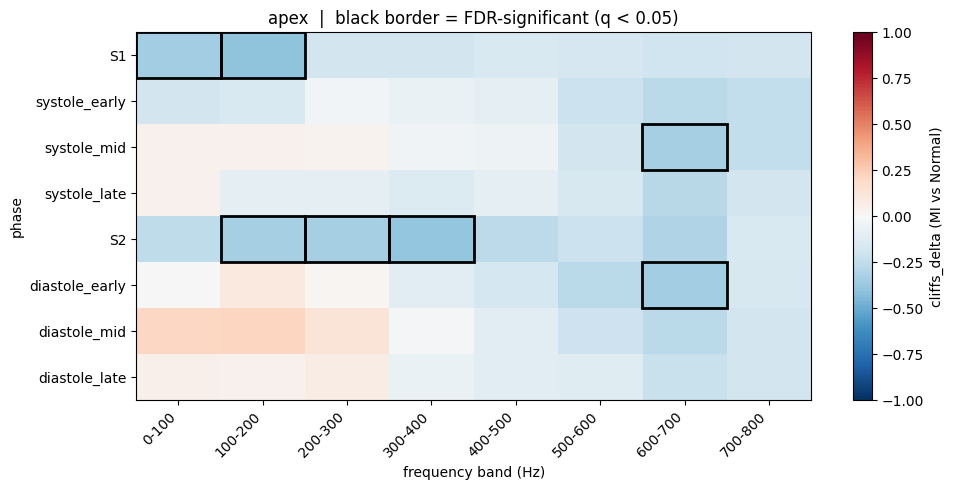

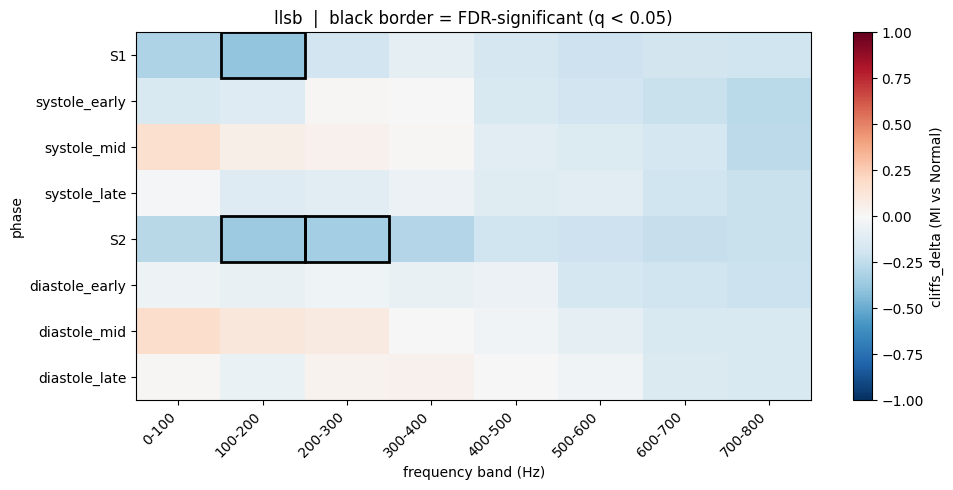

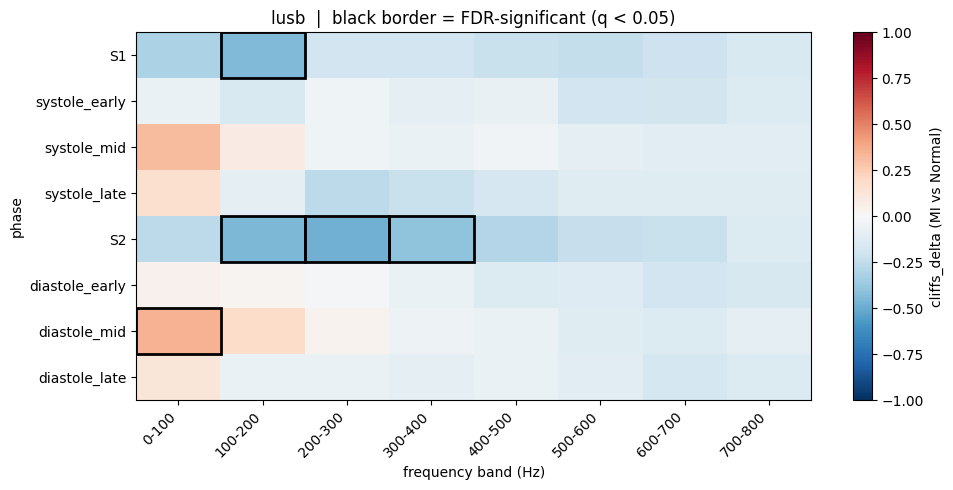

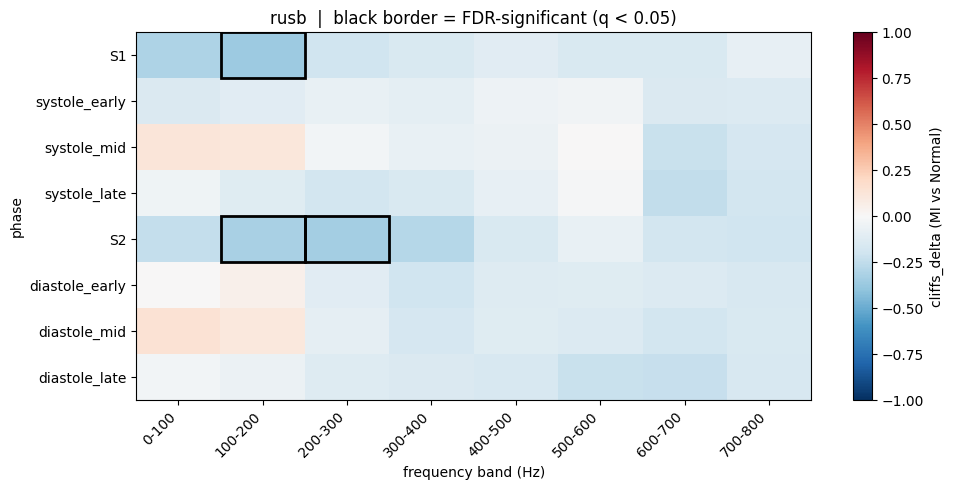

In [7]:
def plot_effect_grid(results_df, site, value_col="cliffs_delta"):
    sub = results_df[results_df["site"] == site]
    freq_labels = sorted(sub[["freq_low", "freq_high"]].drop_duplicates().apply(tuple, axis=1).tolist())
    phases_present = [p for p in PHASE_ORDER if p in sub["phase_label"].unique()]
    if not phases_present or not freq_labels:
        print(f"Nothing to plot for site={site}")
        return

    grid = np.full((len(phases_present), len(freq_labels)), np.nan)
    sig_mask = np.zeros_like(grid, dtype=bool)
    for i, p in enumerate(phases_present):
        for j, (flo, fhi) in enumerate(freq_labels):
            row = sub[(sub["phase_label"] == p) & (sub["freq_low"] == flo) & (sub["freq_high"] == fhi)]
            if len(row):
                grid[i, j] = row.iloc[0][value_col]
                sig_mask[i, j] = bool(row.iloc[0]["significant"])

    fig, ax = plt.subplots(figsize=(10, 5))
    im = ax.imshow(grid, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(freq_labels)))
    ax.set_xticklabels([f"{int(a)}-{int(b)}" for a, b in freq_labels], rotation=45, ha="right")
    ax.set_yticks(range(len(phases_present))); ax.set_yticklabels(phases_present)
    ax.set_xlabel("frequency band (Hz)"); ax.set_ylabel("phase")
    for i in range(len(phases_present)):
        for j in range(len(freq_labels)):
            if sig_mask[i, j]:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False,
                                          edgecolor="black", linewidth=2))
    plt.colorbar(im, label=f"{value_col} (MI vs Normal)")
    ax.set_title(f"{site}  |  black border = FDR-significant (q < {config.FDR_ALPHA})")
    plt.tight_layout(); plt.show()

for site in sorted(results_df["site"].unique()):
    plot_effect_grid(results_df, site)

## 5. Fold stability

For every testable cell: does the direction of the MI-vs-Normal difference agree across each
fold's own held-out patients, or did the pooled result depend on which patients happened to
land where?

In [8]:
stability_rows = []
for _, row in results_df[~results_df["insufficient_data"]].iterrows():
    agree, total = check_fold_stability(patient_energy_df, row)
    stability_rows.append({"agree": agree, "total": total})

results_df["fold_agree"] = np.nan
results_df["fold_total"] = np.nan
if stability_rows:
    # (guarded: an empty stability_rows list would build a DataFrame with no columns at all,
    # not just no rows, so indexing "agree"/"total" out of it would raise a bare KeyError --
    # if you're hitting this branch, n_testable was 0 in Section 3, see its diagnostics)
    tested_index = results_df[~results_df["insufficient_data"]].index
    stability_df = pd.DataFrame(stability_rows, index=tested_index)
    results_df.loc[stability_df.index, "fold_agree"] = stability_df["agree"].values
    results_df.loc[stability_df.index, "fold_total"] = stability_df["total"].values
else:
    print("No testable cells from Section 3 -- nothing to check stability on. "
          "Resolve Section 3's diagnostics first.")
results_df["fold_stability_frac"] = results_df["fold_agree"] / results_df["fold_total"]

if stability_rows:
    print(results_df[~results_df["insufficient_data"]].sort_values("p_value").head(10)
          [["site", "phase_label", "freq_low", "freq_high", "p_value", "significant",
           "fold_agree", "fold_total", "fold_stability_frac"]])

     site   phase_label  freq_low  freq_high   p_value  significant  \
138  lusb            S2     200.0      300.0  0.000012         True   
137  lusb            S2     100.0      200.0  0.000047         True   
129  lusb            S1     100.0      200.0  0.000051         True   
139  lusb            S2     300.0      400.0  0.000261         True   
1    apex            S1     100.0      200.0  0.000270         True   
65   llsb            S1     100.0      200.0  0.000312         True   
11   apex            S2     300.0      400.0  0.000496         True   
73   llsb            S2     100.0      200.0  0.000828         True   
193  rusb            S1     100.0      200.0  0.000901         True   
160  lusb  diastole_mid       0.0      100.0  0.001442         True   

     fold_agree  fold_total  fold_stability_frac  
138         5.0         5.0                  1.0  
137         5.0         5.0                  1.0  
129         5.0         5.0                  1.0  
139         4.

## 6. Shortlist for occlusion testing

Significant + stable, ranked by p-value, capped at `TOP_K_CANDIDATES_FOR_OCCLUSION` — occlusion
is the expensive step (re-running the classifier many times per candidate), so it's only worth
doing for the candidates that already cleared the cheaper bars.

In [9]:
stable_significant = results_df[
    (results_df["significant"]) & (results_df["fold_stability_frac"] > config.FOLD_STABILITY_THRESHOLD)
].copy()

print(f"{len(stable_significant)} candidates are both FDR-significant and fold-stable "
      f"(>{config.FOLD_STABILITY_THRESHOLD*100:.0f}% fold agreement)")

shortlist = stable_significant.sort_values("p_value").head(config.TOP_K_CANDIDATES_FOR_OCCLUSION)
print(f"Occlusion-testing the top {len(shortlist)}:")
print(shortlist[["site", "phase_label", "freq_low", "freq_high", "p_value", "cliffs_delta", "fold_stability_frac"]])

18 candidates are both FDR-significant and fold-stable (>50% fold agreement)
Occlusion-testing the top 10:
     site   phase_label  freq_low  freq_high   p_value  cliffs_delta  \
138  lusb            S2     200.0      300.0  0.000012     -0.480867   
137  lusb            S2     100.0      200.0  0.000047     -0.446429   
129  lusb            S1     100.0      200.0  0.000051     -0.444515   
139  lusb            S2     300.0      400.0  0.000261     -0.400510   
1    apex            S1     100.0      200.0  0.000270     -0.401299   
65   llsb            S1     100.0      200.0  0.000312     -0.395408   
11   apex            S2     300.0      400.0  0.000496     -0.383766   
73   llsb            S2     100.0      200.0  0.000828     -0.366709   
193  rusb            S1     100.0      200.0  0.000901     -0.364158   
160  lusb  diastole_mid       0.0      100.0  0.001442      0.349490   

     fold_stability_frac  
138                  1.0  
137                  1.0  
129                

## 7. Occlusion (causal) validation

For each shortlisted candidate: mask its exact (frequency band, this-recording's-own phase
time interval(s)) region and measure the classifier's accuracy drop, compared against masking
`N_RANDOM_CONTROLS` randomly-placed regions of the same size. `percentile_vs_random` close to 1
means the candidate region mattered more than nearly every random region tried; that's the
causal signal, not just "the heatmap happened to be bright there."

**Runtime note**: this re-runs the classifier once per recording per candidate per random
control, so it scales with shortlist size x recordings x `N_RANDOM_CONTROLS`.

In [10]:
# Columns the occlusion table needs even when the shortlist is empty -- an empty
# pd.DataFrame([]) has NO columns at all (not just no rows), which would save an unparseable
# CSV and break Stage 5's read of it. Always saving with the right schema, even at zero rows,
# is what makes "no candidates survived" a clean, machine-readable result instead of a crash
# two stages later.
OCCLUSION_COLUMNS = [
    "site", "phase_label", "freq_low", "freq_high", "n_mi", "n_normal",
    "median_mi", "median_normal", "cliffs_delta", "p_value", "insufficient_data",
    "fdr_q_value", "significant", "fold_agree", "fold_total", "fold_stability_frac",
    "n_recordings_tested", "baseline_accuracy", "occluded_accuracy", "occlusion_effect",
    "random_control_effects", "percentile_vs_random", "occlusion_validated",
]

occlusion_rows = []
for _, candidate in shortlist.iterrows():
    print(f"Occlusion testing: {candidate['site']} | {candidate['phase_label']} | "
          f"{candidate['freq_low']:.0f}-{candidate['freq_high']:.0f} Hz ...")
    result = run_occlusion_test(
        candidate, oof_df, boundaries_df, fold_models, DEVICE, config,
        n_random_controls=config.N_RANDOM_CONTROLS, seed=config.OCCLUSION_SEED,
    )
    occlusion_rows.append({**candidate.to_dict(), **result})

if occlusion_rows:
    occlusion_df = pd.DataFrame(occlusion_rows)
    occlusion_df["occlusion_validated"] = occlusion_df["percentile_vs_random"] >= 0.95
    print(f"\n{occlusion_df['occlusion_validated'].sum()} of {len(occlusion_df)} "
          f"shortlisted candidates passed occlusion validation (percentile >= 0.95)")
    print(occlusion_df[["site", "phase_label", "freq_low", "freq_high", "baseline_accuracy",
                        "occluded_accuracy", "occlusion_effect", "percentile_vs_random",
                        "occlusion_validated"]])
else:
    occlusion_df = pd.DataFrame(columns=OCCLUSION_COLUMNS)
    # Explicit bool dtype: an empty column defaults to dtype 'object', and boolean-masking
    # with a non-bool empty Series silently drops every column (not just every row) -- without
    # this cast, filtering by it below would produce a DataFrame with no columns at all, right
    # back to the same class of bug this whole schema was added to avoid.
    occlusion_df["occlusion_validated"] = occlusion_df["occlusion_validated"].astype(bool)
    print("Shortlist was empty -- nothing to occlusion-test.")

Occlusion testing: lusb | S2 | 200-300 Hz ...
Occlusion testing: lusb | S2 | 100-200 Hz ...
Occlusion testing: lusb | S1 | 100-200 Hz ...
Occlusion testing: lusb | S2 | 300-400 Hz ...
Occlusion testing: apex | S1 | 100-200 Hz ...
Occlusion testing: llsb | S1 | 100-200 Hz ...
Occlusion testing: apex | S2 | 300-400 Hz ...
Occlusion testing: llsb | S2 | 100-200 Hz ...
Occlusion testing: rusb | S1 | 100-200 Hz ...
Occlusion testing: lusb | diastole_mid | 0-100 Hz ...

2 of 10 shortlisted candidates passed occlusion validation (percentile >= 0.95)
   site   phase_label  freq_low  freq_high  baseline_accuracy  \
0  lusb            S2     200.0      300.0           0.892857   
1  lusb            S2     100.0      200.0           0.892857   
2  lusb            S1     100.0      200.0           0.892857   
3  lusb            S2     300.0      400.0           0.892857   
4  apex            S1     100.0      200.0           0.880845   
5  llsb            S1     100.0      200.0           0.914925

## 8. Final candidate markers (development-set)

In [11]:
final_candidates = occlusion_df[occlusion_df["occlusion_validated"]].sort_values("p_value")

print("=" * 70)
print(f"FINAL CANDIDATE MARKERS ({len(final_candidates)})")
print("=" * 70)

if len(final_candidates) == 0:
    print("\nNone of the shortlisted candidates passed occlusion validation on the development")
    print("set. This is a legitimate, reportable result -- not every statistically significant")
    print("cell survives a causal check, and catching that distinction is the point of doing one.")
else:
    for _, c in final_candidates.iterrows():
        direction = "higher" if c["median_mi"] > c["median_normal"] else "lower"
        print(f"\n{c['phase_label']} + {c['freq_low']:.0f}-{c['freq_high']:.0f} Hz + {c['site']}:")
        print(f"    MI energy {direction} than Normal (median {c['median_mi']:.4f} vs {c['median_normal']:.4f})")
        print(f"    Cliff's delta: {c['cliffs_delta']:.3f}  |  FDR q-value: {c['fdr_q_value']:.4f}")
        print(f"    Fold stability: {int(c['fold_agree'])}/{int(c['fold_total'])} folds agree in direction")
        print(f"    Occlusion: accuracy {c['baseline_accuracy']:.3f} -> {c['occluded_accuracy']:.3f} when masked "
              f"(beats {c['percentile_vs_random']*100:.0f}% of random-region controls)")
    print("\nThese are DEVELOPMENT-SET candidates. Stage 5 checks whether they replicate on the")
    print("locked confirmation cohort -- that is the step that actually validates them.")

FINAL CANDIDATE MARKERS (2)

S2 + 200-300 Hz + lusb:
    MI energy lower than Normal (median 0.1414 vs 0.2044)
    Cliff's delta: -0.481  |  FDR q-value: 0.0030
    Fold stability: 5/5 folds agree in direction
    Occlusion: accuracy 0.893 -> 0.871 when masked (beats 100% of random-region controls)

S1 + 100-200 Hz + apex:
    MI energy lower than Normal (median 0.1567 vs 0.2247)
    Cliff's delta: -0.401  |  FDR q-value: 0.0133
    Fold stability: 5/5 folds agree in direction
    Occlusion: accuracy 0.881 -> 0.848 when masked (beats 100% of random-region controls)

These are DEVELOPMENT-SET candidates. Stage 5 checks whether they replicate on the
locked confirmation cohort -- that is the step that actually validates them.


## 9. Save this stage's outputs

In [12]:
recording_energy_df.to_csv(STAGE_DIR / "recording_energy_table.csv", index=False)
patient_energy_df.to_csv(STAGE_DIR / "patient_energy_table.csv", index=False)
results_df.to_csv(STAGE_DIR / "statistical_test_results.csv", index=False)
occlusion_df.to_csv(STAGE_DIR / "occlusion_results.csv", index=False)
final_candidates.to_csv(STAGE_DIR / "candidate_markers_final.csv", index=False)

config_used = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "frequency_band_width_hz": config.FREQUENCY_BAND_WIDTH_HZ,
    "energy_aggregation": config.ENERGY_AGGREGATION,
    "min_patients_per_group_for_test": config.MIN_PATIENTS_PER_GROUP_FOR_TEST,
    "fdr_alpha": config.FDR_ALPHA,
    "fold_stability_threshold": config.FOLD_STABILITY_THRESHOLD,
    "top_k_candidates_for_occlusion": config.TOP_K_CANDIDATES_FOR_OCCLUSION,
    "n_random_controls": config.N_RANDOM_CONTROLS,
    "n_cells_tested": int((~results_df["insufficient_data"]).sum()),
    "n_significant": int(results_df["significant"].sum()),
    "n_significant_and_stable": int(len(stable_significant)),
    "n_occlusion_validated": int(len(final_candidates)),
}
with open(STAGE_DIR / "config_used.json", "w") as f:
    json.dump(config_used, f, indent=2, default=str)

print("Saved:")
print(f"  {STAGE_DIR / 'recording_energy_table.csv'}  ({len(recording_energy_df)} rows)")
print(f"  {STAGE_DIR / 'patient_energy_table.csv'}  ({len(patient_energy_df)} rows)")
print(f"  {STAGE_DIR / 'statistical_test_results.csv'}  ({len(results_df)} cells)")
print(f"  {STAGE_DIR / 'occlusion_results.csv'}  ({len(occlusion_df)} candidates tested)")
print(f"  {STAGE_DIR / 'candidate_markers_final.csv'}  ({len(final_candidates)} validated)")
print(f"  {STAGE_DIR / 'config_used.json'}")

Saved:
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/04_candidate_discovery/recording_energy_table.csv  (171520 rows)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/04_candidate_discovery/patient_energy_table.csv  (28608 rows)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/04_candidate_discovery/statistical_test_results.csv  (256 cells)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/04_candidate_discovery/occlusion_results.csv  (10 candidates tested)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/04_candidate_discovery/candidate_markers_final.csv  (2 validated)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/04_candidate_discovery/config_used.json


## Next: Stage 5

Stage 5 takes `candidate_markers_final.csv` and replicates the exact same statistical test —
unchanged, no re-tuning, no re-searching — on the confirmation cohort that has been locked away
since Stage 1. A candidate that replicates there is what finally earns the label "acoustic
marker of MI", patient-independent, as the research question set out to establish.